<a href="https://colab.research.google.com/github/nizarbanu/Active-Contours/blob/main/Active_Contours_Learner_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Learner Notebook: Active Contours (Snake) for Image Segmentation

**Topic:** Active Contours / Snake Model  
**Practical focus:** Object boundary detection and contour refinement using Python, OpenCV, SciPy and scikit-image.

## Learning outcomes

After completing this notebook, you should be able to:

1. Load an image and prepare RGB and grayscale representations.
2. Obtain a binary object mask using background-colour distance and Otsu thresholding.
3. Extract an initial object boundary using `cv2.findContours()`.
4. Explain the internal and external energy of an active contour.
5. Initialize and evolve a closed snake around an object.
6. Investigate the influence of the parameters alpha (α) and beta (β).
7. Compare a custom snake implementation with `skimage.segmentation.active_contour`.
8. Explain why the initial position of a snake affects segmentation.

## Background

An **Active Contour**, also called a **Snake**, is a curve that moves towards an object's boundary. The contour is refined by balancing:

- **Internal energy:** Controls the shape, smoothness and continuity of the contour.
- **External energy:** Uses image information to attract the contour towards the object boundary.

The contour is represented by a set of points. During iterations, these points move until the contour reaches a stable position near the target boundary.

## Libraries used

- OpenCV (`cv2`) – image processing and contour extraction
- NumPy – numerical operations and matrix calculations
- Matplotlib – visualization
- SciPy – distance transform and coordinate interpolation
- scikit-image – built-in active contour implementation

**Input image:** The supplied practical uses `shinchan_cv.webp`. If this image is unavailable, the notebook automatically generates a synthetic irregular object for understanding.

## 1. Import libraries

Run the following cell to import the required libraries and initialize the random seed. A fixed random seed helps produce a repeatable synthetic example.

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates, distance_transform_edt
from skimage.filters import threshold_otsu, gaussian
from skimage.segmentation import active_contour

np.random.seed(7)
plt.rcParams["figure.facecolor"] = "white"


## 2. Load the image and prepare the input

The notebook first checks whether `shinchan_cv.webp` is available.

- If the image exists, it is loaded and converted from BGR to RGB.
- If the image is not available, a synthetic irregular, non-convex shape is generated.
- The RGB image is also converted to grayscale for image-processing operations.

**Observe:** Compare the RGB and grayscale images. The RGB image contains colour information, while the grayscale image represents intensity values.

'shinchan_cv.webp' not found -> using a generated synthetic irregular shape
RGB image shape:       (300, 300, 3)
Grayscale image shape: (300, 300)


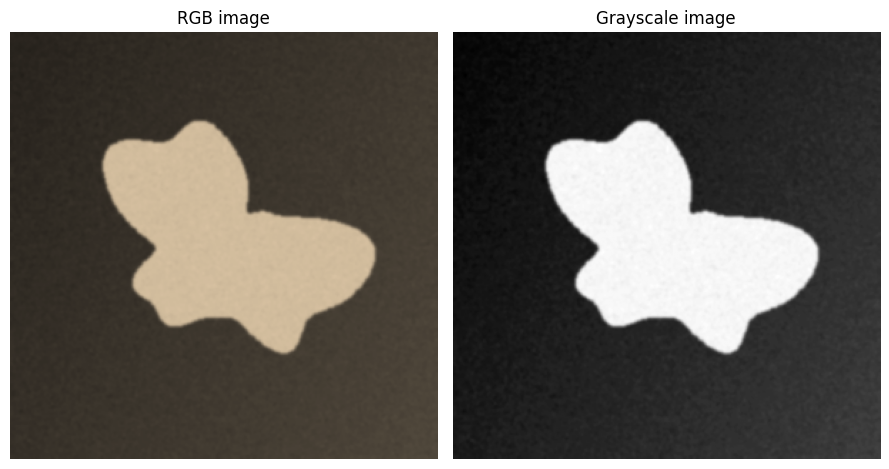

In [2]:
IMAGE_PATH = "shinchan_cv.webp"   # <- change this to use a different image


def generate_irregular_shape_image(size=300, cx=150, cy=150, base_radius=70, seed=7):
    """Fallback: create an RGB image containing one irregular, non-convex blob."""
    rng = np.random.default_rng(seed)
    theta = np.linspace(0, 2*np.pi, 400)
    harmonics = [(2, 22, 0.3), (3, 16, 1.1), (5, 9, 2.0), (7, 6, 0.7), (11, 3, 2.6)]
    radius = np.full_like(theta, base_radius)
    for k, amp, phase in harmonics:
        radius = radius + amp*np.sin(k*theta + phase)
    xs = (cx + radius*np.cos(theta)).astype(np.int32)
    ys = (cy + radius*np.sin(theta)).astype(np.int32)
    pts = np.stack([xs, ys], axis=1).reshape(-1, 1, 2)
    gx, gy = np.meshgrid(np.linspace(0, 1, size), np.linspace(0, 1, size))
    canvas = 40 + 25*gx + 15*gy
    mask = np.zeros((size, size), dtype=np.uint8)
    cv2.fillPoly(mask, [pts], 255)
    canvas[mask == 255] = 210
    canvas = canvas + rng.normal(0, 6, size=canvas.shape)
    canvas = np.clip(canvas, 0, 255).astype(np.uint8)
    canvas = cv2.GaussianBlur(canvas, (5, 5), 1.0)
    rgb = cv2.cvtColor(canvas, cv2.COLOR_GRAY2RGB)
    return np.clip(rgb.astype(np.float64)*np.array([1.0, 0.9, 0.75]), 0, 255).astype(np.uint8)


if os.path.exists(IMAGE_PATH):
    bgr = cv2.imread(IMAGE_PATH)
    rgb_img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    print(f"Loaded '{IMAGE_PATH}'")
else:
    rgb_img = generate_irregular_shape_image()
    print(f"'{IMAGE_PATH}' not found -> using a generated synthetic irregular shape")

gray_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY)

print("RGB image shape:      ", rgb_img.shape)
print("Grayscale image shape:", gray_img.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 6))
axes[0].imshow(rgb_img);              axes[0].set_title("RGB image");        axes[0].axis("off")
axes[1].imshow(gray_img, cmap="gray");axes[1].set_title("Grayscale image");  axes[1].axis("off")
plt.tight_layout(); plt.show()


## 3. Binary thresholded image

The object must be separated from its background before extracting its initial contour.

A direct Otsu threshold on grayscale intensity may not separate a multi-coloured object correctly. In this practical, the background colour is estimated from the image corners. For each pixel, the colour distance from this estimated background is calculated.

Otsu's thresholding method is then applied to the distance image to separate the object from the background. A morphological closing operation fills small gaps in the binary mask.

**Key terms**

- **Background colour:** Estimated using pixels from the image corners.
- **Colour distance:** Difference between a pixel's colour and the estimated background colour.
- **Otsu thresholding:** Automatically selects a threshold to separate two intensity groups.
- **Morphological closing:** Fills small gaps and holes in foreground regions.

Estimated background colour (RGB): [59.58 53.15 44.34]
Otsu threshold (on background-distance image): 117.0


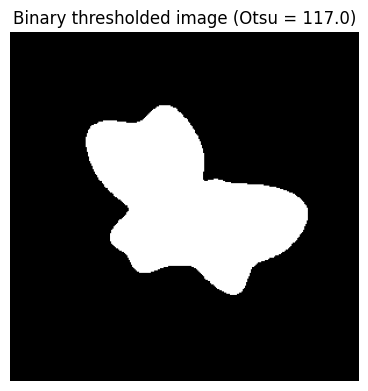

In [3]:
# Estimate background colour from the image corners (assumes a fairly uniform background)
corner_px = np.concatenate([
    rgb_img[:5, :5].reshape(-1, 3), rgb_img[:5, -5:].reshape(-1, 3),
    rgb_img[-5:, :5].reshape(-1, 3), rgb_img[-5:, -5:].reshape(-1, 3)
], axis=0)
bg_color = corner_px.mean(axis=0)

diff = np.linalg.norm(rgb_img.astype(np.float64) - bg_color, axis=2)
diff_u8 = np.clip(diff, 0, 255).astype(np.uint8)
otsu_thresh = threshold_otsu(diff_u8)

binary_img = (diff_u8 > otsu_thresh).astype(np.uint8) * 255
kernel = np.ones((3, 3), np.uint8)
# Closing only: fills tiny internal gaps without eroding away thin outline strokes
# (an opening here would erase thin connecting lines and fragment the silhouette).
binary_img = cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel)

print(f"Estimated background colour (RGB): {bg_color}")
print(f"Otsu threshold (on background-distance image): {otsu_thresh:.1f}")

plt.figure(figsize=(4.5, 6))
plt.imshow(binary_img, cmap="gray")
plt.title(f"Binary thresholded image (Otsu = {otsu_thresh:.1f})")
plt.axis("off"); plt.show()


## 4. Initial object contour detection

The binary mask provides an initial estimate of the object's boundary. OpenCV's `cv2.findContours()` function extracts contours from the binary image.

The practical uses:

- `cv2.RETR_EXTERNAL` – retrieves only the external contours.
- `cv2.CHAIN_APPROX_NONE` – stores all contour boundary points.
- `cv2.contourArea()` – calculates the area enclosed by a contour.

The largest contour is selected and drawn over the original RGB image.

**Important:** This is a threshold-based boundary. The active contour model will be used in later steps to refine the boundary.

Number of contours found: 1


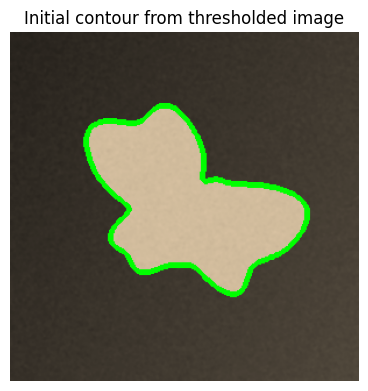

Largest contour:  541 points, area = 16759.5


In [4]:
contours, _ = cv2.findContours(binary_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
print("Number of contours found:", len(contours))

largest_contour = max(contours, key=cv2.contourArea)
contour_overlay = rgb_img.copy()
cv2.drawContours(contour_overlay, [largest_contour], -1, (0, 255, 0), 3)

plt.figure(figsize=(4.5, 6))
plt.imshow(contour_overlay)
plt.title("Initial contour from thresholded image")
plt.axis("off"); plt.show()

print("Largest contour: ", largest_contour.shape[0], "points, area =",
      cv2.contourArea(largest_contour))


## 5. Internal energy of the snake

The internal energy controls the shape of the contour.

Two important parameters are used:

- **Alpha (α) – elasticity / tension:** Controls the tendency of the contour to contract or remain smooth in its spacing.
- **Beta (β) – bending / stiffness:** Controls resistance to sharp bending and encourages a smoother contour.

The function below constructs the internal-energy matrix for a closed contour. Periodic boundary conditions are used because the snake is a closed curve.

The matrix is combined with gamma (γ) and inverted. The inverse is used during the iterative contour update.

**Observe:** The matrix visualization shows the structure of the inverse internal-energy matrix.

Internal energy matrix inverse shape: (100, 100)


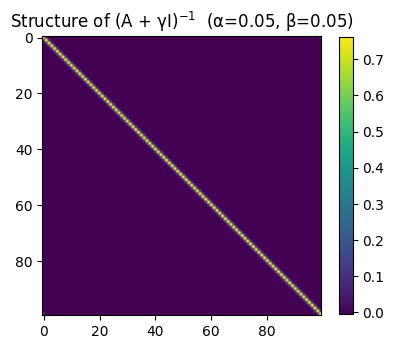

In [5]:
def build_internal_energy_inverse(n_points, alpha, beta, gamma):
    """
    Build (A + gamma*I)^-1 for a CLOSED snake of n_points, following
    Kass, Witkin & Terzopoulos (1988).

    Each row of A encodes the discretized second derivative (elasticity, alpha)
    and fourth derivative (bending, beta) operators about a point on the closed
    contour (circulant / periodic boundary conditions), giving a pentadiagonal
    band structure:

        A[i, i]       =  2*alpha + 6*beta
        A[i, i-1]     = -(alpha + 4*beta)
        A[i, i+1]     = -(alpha + 4*beta)
        A[i, i-2]     =  beta
        A[i, i+2]     =  beta
    """
    A = np.zeros((n_points, n_points))
    for i in range(n_points):
        A[i, i] = 2*alpha + 6*beta
        A[i, (i - 1) % n_points] += -(alpha + 4*beta)
        A[i, (i + 1) % n_points] += -(alpha + 4*beta)
        A[i, (i - 2) % n_points] += beta
        A[i, (i + 2) % n_points] += beta
    return np.linalg.inv(A + gamma*np.eye(n_points))


# --- Demonstration: build and visualise the matrix structure ---
n_pts_demo = 100
Ainv_demo = build_internal_energy_inverse(n_pts_demo, alpha=0.05, beta=0.05, gamma=1.0)
print("Internal energy matrix inverse shape:", Ainv_demo.shape)

plt.figure(figsize=(4.5, 4.5))
plt.imshow(Ainv_demo, cmap="viridis")
plt.title("Structure of (A + γI)$^{-1}$  (α=0.05, β=0.05)")
plt.colorbar(shrink=0.8)
plt.show()


## 6. External energy and snake initialization

### External energy

The external force attracts the snake towards the object boundary. In this practical, a distance transform is calculated from the boundary of the binary mask. The gradient of the distance transform provides a force direction towards the nearest boundary.

This approach is used to reduce the influence of internal edges such as facial features or clothing details.

### Initial contour

The snake is initialized as an ellipse around the object's bounding box. The initial contour should enclose the object and be reasonably close to its boundary.

### Snake evolution

The custom implementation updates the contour iteratively using:

1. Internal energy, controlled by α and β.
2. External image forces.
3. A small balloon force along the contour normal.
4. The current contour coordinates.

The balloon force helps the contour move through certain concave regions where the distance-based force may become weak.

**Key point:** The initial position and the parameter values influence the final segmentation.

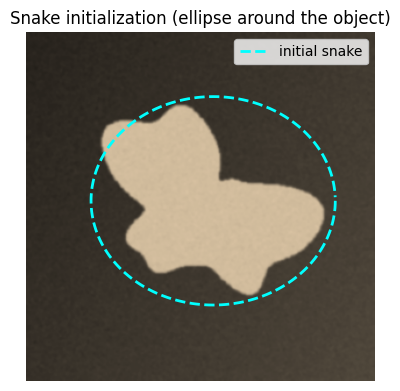

In [6]:
def external_energy_forces_distance(mask01):
    """External force field: at every pixel, points toward the nearest boundary
    pixel of the (binary) object mask. Robust to interior edges/details."""
    edge = cv2.Canny((mask01*255).astype(np.uint8), 50, 150)
    dist = distance_transform_edt(edge == 0)      # distance to nearest boundary pixel
    gy, gx = np.gradient(dist)
    fx, fy = -gx, -gy                              # force points toward the boundary
    mag = np.hypot(fx, fy)
    return fx/(mag.max() + 1e-12), fy/(mag.max() + 1e-12)


def init_ellipse_snake(cx, cy, rx, ry, n_points=180):
    theta = np.linspace(0, 2*np.pi, n_points, endpoint=False)
    return cx + rx*np.cos(theta), cy + ry*np.sin(theta)


def run_custom_snake(force_fields, shape, x, y, alpha, beta, gamma=1.0, n_iters=300,
                      force_scale=3.0, balloon=0.7, snapshot_iters=None):
    """
    Evolve a closed snake using the internal-energy matrix + external forces
    + a small BALLOON (inflation) force along the curve's own local normal.

    Why the balloon term is needed: a purely distance-based external force has
    a "ridge" (a locus of points equidistant from two different boundary
    segments) wherever the object has a concave notch -- e.g. exactly in the
    gap between two legs. Along that ridge the external force is essentially
    zero, so a point that lands there is pulled only by its neighbours'
    internal (elastic) energy, which settles it onto the straight chord
    between them instead of following the true concave boundary. A small,
    constant push along the local curve normal (Cohen, 1991) is enough to
    nudge such points off this false equilibrium so they keep moving until
    they reach a region with real edge attraction again.
    """
    fx_field, fy_field = force_fields
    n_points = len(x)
    Ainv = build_internal_energy_inverse(n_points, alpha, beta, gamma)
    h, w = shape
    snapshots = {}
    if snapshot_iters is not None and 0 in snapshot_iters:
        snapshots[0] = (x.copy(), y.copy())
    cxg, cyg = x.mean(), y.mean()

    for it in range(1, n_iters + 1):
        xc, yc = np.clip(x, 0, w - 1), np.clip(y, 0, h - 1)
        fx = force_scale * map_coordinates(fx_field, [yc, xc], order=1)
        fy = force_scale * map_coordinates(fy_field, [yc, xc], order=1)

        # local outward/inward normal, estimated from neighbouring snake points
        xt, yt = np.roll(x, -1) - np.roll(x, 1), np.roll(y, -1) - np.roll(y, 1)
        seg_len = np.hypot(xt, yt) + 1e-9
        nx, ny = -yt / seg_len, xt / seg_len
        # orient it to point INWARD (toward the current centroid) for consistency
        sign = np.sign(nx*(cxg - x) + ny*(cyg - y))
        fx, fy = fx + balloon*nx*sign, fy + balloon*ny*sign

        x = np.clip(Ainv @ (gamma*x + fx), 0, w - 1)
        y = np.clip(Ainv @ (gamma*y + fy), 0, h - 1)
        if snapshot_iters is not None and it in snapshot_iters:
            snapshots[it] = (x.copy(), y.copy())
    return x, y, snapshots


mask01 = (binary_img > 0).astype(np.float64)
forces = external_energy_forces_distance(mask01)

# Initialize the snake as an ELLIPSE sized to the object's bounding box
# (a plain circle fits a tall/narrow figure like this one poorly)
bx, by, bw, bh = cv2.boundingRect(binary_img)
cx0, cy0 = bx + bw/2, by + bh/2
rx0, ry0 = 0.55*bw, 0.55*bh
x0, y0 = init_ellipse_snake(cx0, cy0, rx0, ry0, n_points=180)

plt.figure(figsize=(4.5, 6))
plt.imshow(rgb_img)
plt.plot(x0, y0, "--", color="cyan", lw=2, label="initial snake")
plt.legend(); plt.axis("off")
plt.title("Snake initialization (ellipse around the object)")
plt.show()


## 7. Baseline snake evolution

The baseline experiment uses small, balanced values of α and β. The snake starts from the initializing ellipse and evolves towards the object's irregular boundary.

The contour positions are saved at selected iterations so that the movement can be visualized.

**Observe:**

- The cyan curve represents the initial contour.
- The red curve represents the final segmented contour.
- Compare the final contour with the visible object boundary, including concave regions.

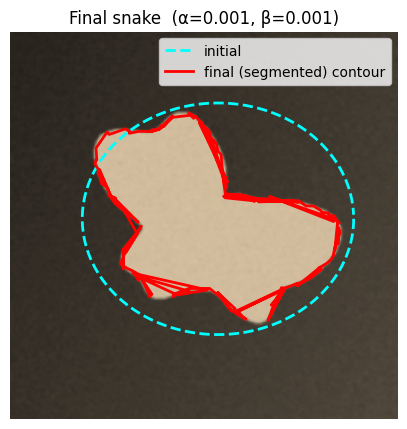

In [7]:
BASE_ALPHA, BASE_BETA = 0.001, 0.001   # a small, well-behaved (default) setting

x_f, y_f, snaps = run_custom_snake(
    forces, gray_img.shape, x0, y0, alpha=BASE_ALPHA, beta=BASE_BETA, gamma=1.0,
    n_iters=300, force_scale=3.0, snapshot_iters=[0, 20, 60, 120, 200, 300]
)

fig, ax = plt.subplots(figsize=(5, 7))
ax.imshow(rgb_img)
ax.plot(x0, y0, "--", color="cyan", lw=2, label="initial")
ax.plot(x_f, y_f, "-", color="red", lw=2, label="final (segmented) contour")
ax.legend(); ax.axis("off")
ax.set_title(f"Final snake  (α={BASE_ALPHA}, β={BASE_BETA})")
plt.show()


## 8. Effect of alpha (α) and beta (β)

The parameters α and β influence the flexibility and smoothness of the snake.

The practical investigates several combinations:

| Parameter setting | Expected influence |
|---|---|
| Very low α and very low β | More flexible contour; can follow irregular details |
| High α and low β | Stronger tension with weaker bending resistance |
| Low α and high β | Stronger resistance to bending; smoother contour |
| Moderate α and β | Balanced contour behaviour |
| Very high α and β | Strong internal constraints; contour may deform very little |

Run the next cell and compare the resulting contours. The same image and initial contour are used for each parameter combination.

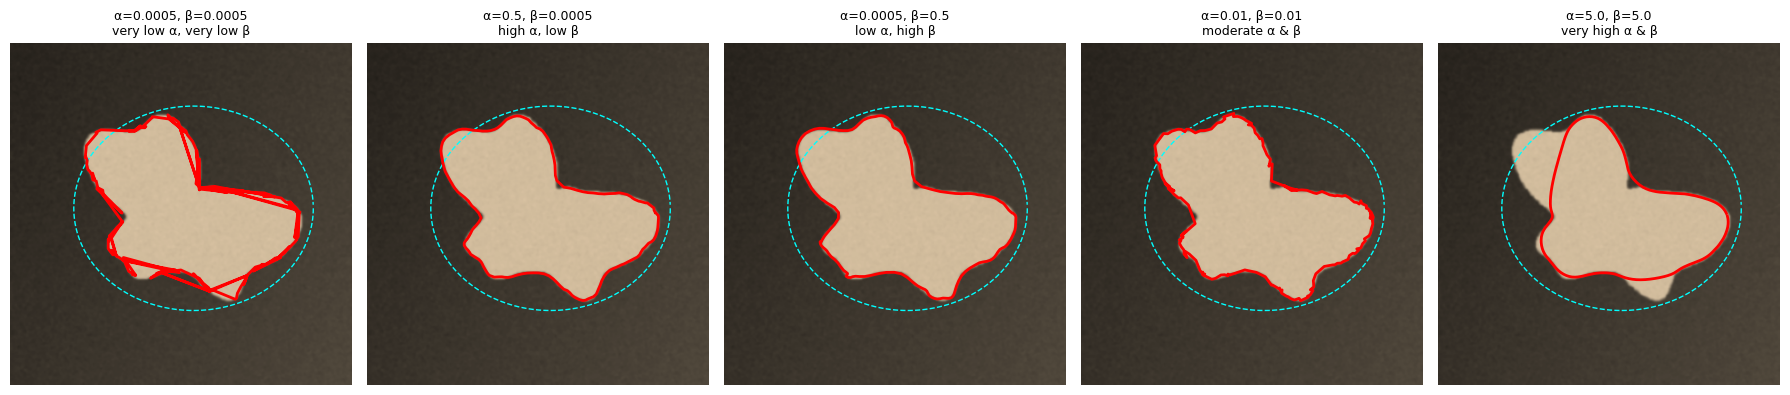

In [8]:
param_sets = [
    (0.0005, 0.0005, "very low α, very low β"),
    (0.5,    0.0005, "high α, low β"),
    (0.0005, 0.5,    "low α, high β"),
    (0.01,   0.01,   "moderate α & β"),
    (5.0,    5.0,    "very high α & β"),
]

fig, axes = plt.subplots(1, len(param_sets), figsize=(3.6*len(param_sets), 6))
for ax, (a, b, label) in zip(axes, param_sets):
    xr, yr, _ = run_custom_snake(forces, gray_img.shape, x0.copy(), y0.copy(),
                                  alpha=a, beta=b, gamma=1.0, n_iters=300, force_scale=3.0)
    ax.imshow(rgb_img)
    ax.plot(x0, y0, "--", color="cyan", lw=1)
    ax.plot(xr, yr, "-", color="red", lw=2)
    ax.set_title(f"α={a}, β={b}\n{label}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()


## 9. Cross-check using scikit-image active contour

The custom snake implementation is compared with the built-in `active_contour()` function from scikit-image.

The same parameter sets are used to investigate how α and β influence the contour produced by the library implementation.

**Note:** The scikit-image function expects contour coordinates in `(row, column)` order, which corresponds to `(y, x)`. This is why the initial snake is arranged as `[y0, x0]`.

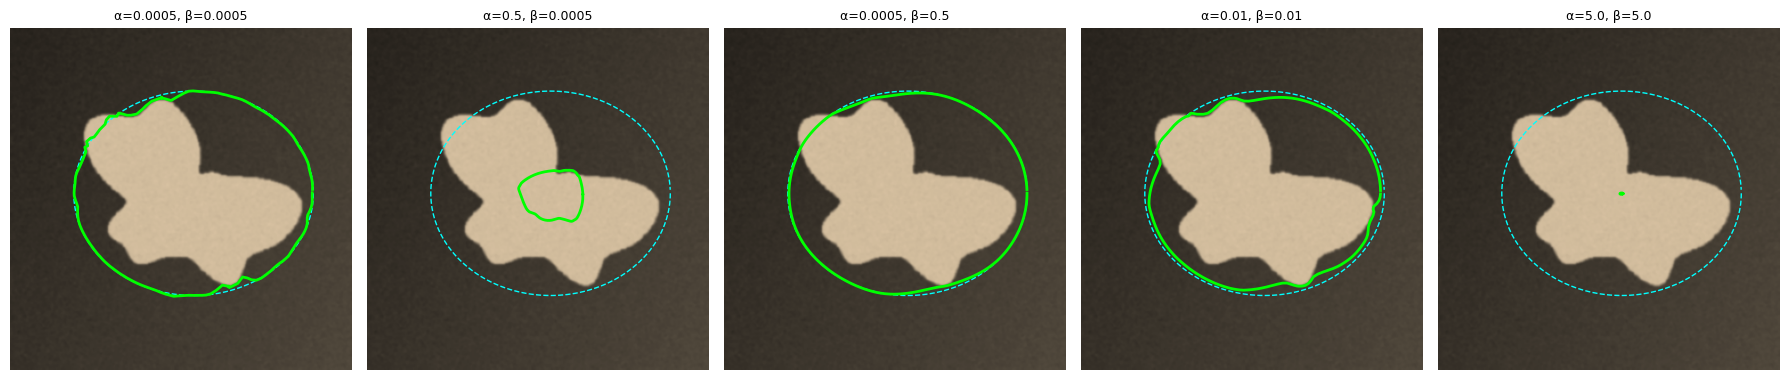

In [9]:
dist_energy = -np.hypot(*np.gradient(
    distance_transform_edt(cv2.Canny((mask01*255).astype(np.uint8), 50, 150) == 0)))
snake_init = np.array([y0, x0]).T   # skimage expects (row, col) = (y, x)

fig, axes = plt.subplots(1, len(param_sets), figsize=(3.6*len(param_sets), 6))
for ax, (a, b, label) in zip(axes, param_sets):
    snk = active_contour(gaussian(-dist_energy, sigma=1, preserve_range=True),
                          snake_init, alpha=a, beta=b, gamma=0.1, max_num_iter=250)
    ax.imshow(rgb_img)
    ax.plot(snake_init[:, 1], snake_init[:, 0], "--", color="cyan", lw=1)
    ax.plot(snk[:, 1], snk[:, 0], "-", color="lime", lw=2)
    ax.set_title(f"α={a}, β={b}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()


### Observations from the parameter investigation

- **Very low α and β:** The snake is flexible and can follow uneven boundaries in greater detail.
- **High α with low β:** Stronger tension and weaker bending resistance can cause the contour to overshoot or produce less faithful boundaries.
- **Low α with high β:** The contour becomes smoother and may not follow sharp concavities.
- **Very high α and β:** The internal energy can dominate the external force, so the contour may barely deform from its initial position.
- The parameters must be selected in relation to the magnitude of the external force.

The experiment also shows that even a well-tuned snake may have difficulty following very narrow concave regions.

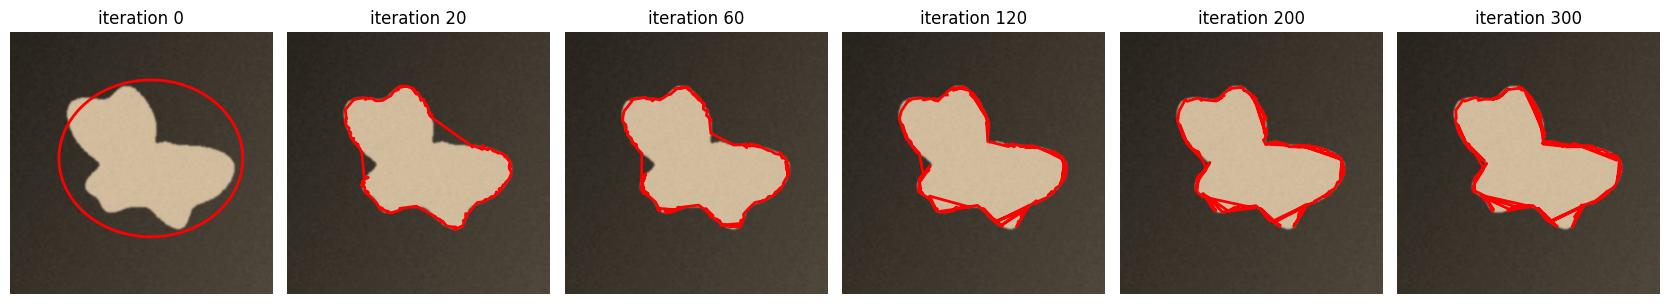

Final segmented contour shown at the last iteration above (300 iterations).


In [10]:
fig, axes = plt.subplots(1, len(snaps), figsize=(2.8*len(snaps), 4.5))
for ax, it in zip(axes, sorted(snaps.keys())):
    xs, ys = snaps[it]
    ax.imshow(rgb_img)
    ax.plot(xs, ys, "-", color="red", lw=2)
    ax.set_title(f"iteration {it}")
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Final segmented contour shown at the last iteration above "
      f"({sorted(snaps.keys())[-1]} iterations).")


## 10. Intermediate contour positions and final segmentation

The next visualization displays the snake at selected iterations. It helps explain that active contour segmentation is an iterative process rather than a one-step boundary detection operation.

**Observe:** Follow the contour from the initial ellipse through the intermediate iterations to the final contour. Note where the contour moves quickly and where it changes more gradually.

## 11. Effect of initializing the snake away from the object boundary

A snake may fail to segment an object if its initial contour is unsuitable. This practical compares:

1. **Good initialization:** An ellipse that encloses the object.
2. **Too-small initialization:** A small circle placed inside the object, around only part of it.
3. **Far-away initialization:** A small circle placed in an empty corner, away from the object.

The external force has a limited capture range. If the snake starts far from the target boundary, the available force may not be sufficient to guide it to the correct boundary. If it starts inside the object, internal edges may attract the contour.

Run the cell and compare the initial and final contours in all three cases.

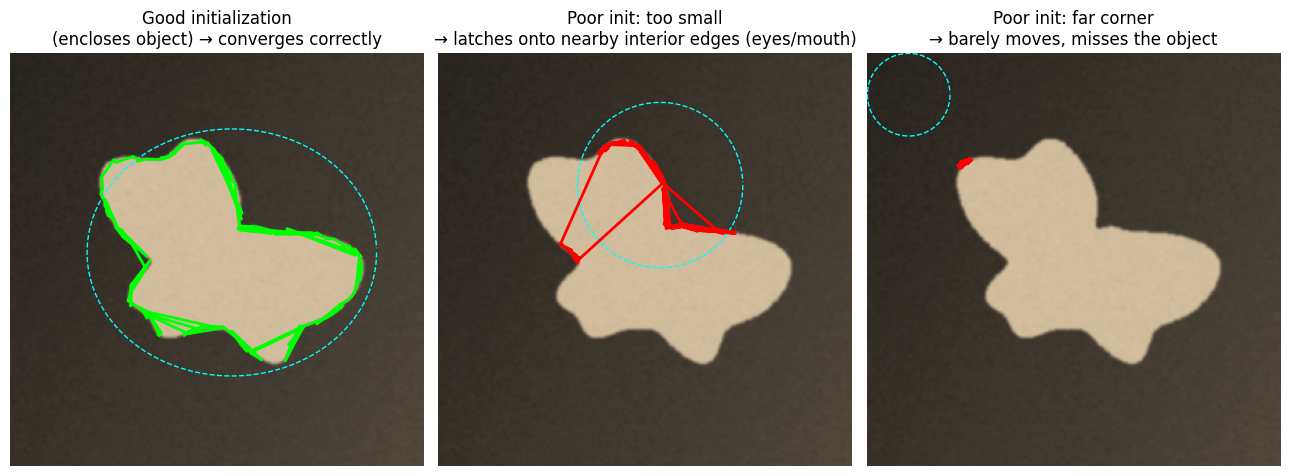

In [11]:
# Poor initialization 1: small circle around the face only (well inside the object)
x_small, y_small = init_ellipse_snake(cx0, cy0 - 0.3*bh, 60, 60, n_points=150)
xr_small, yr_small, _ = run_custom_snake(forces, gray_img.shape, x_small.copy(), y_small.copy(),
                                          alpha=BASE_ALPHA, beta=BASE_BETA, gamma=1.0,
                                          n_iters=300, force_scale=3.0)

# Poor initialization 2: small circle in an empty corner, far from the object
x_far, y_far = init_ellipse_snake(0.1*gray_img.shape[1], 0.1*gray_img.shape[0], 30, 30, n_points=150)
xr_far, yr_far, _ = run_custom_snake(forces, gray_img.shape, x_far.copy(), y_far.copy(),
                                      alpha=BASE_ALPHA, beta=BASE_BETA, gamma=1.0,
                                      n_iters=300, force_scale=3.0)

fig, axes = plt.subplots(1, 3, figsize=(13, 6.5))

axes[0].imshow(rgb_img)
axes[0].plot(x0, y0, "--", color="cyan", lw=1)
axes[0].plot(x_f, y_f, "-", color="lime", lw=2)
axes[0].set_title("Good initialization\n(encloses object) → converges correctly")
axes[0].axis("off")

axes[1].imshow(rgb_img)
axes[1].plot(x_small, y_small, "--", color="cyan", lw=1)
axes[1].plot(xr_small, yr_small, "-", color="red", lw=2)
axes[1].set_title("Poor init: too small\n→ latches onto nearby interior edges (eyes/mouth)")
axes[1].axis("off")

axes[2].imshow(rgb_img)
axes[2].plot(x_far, y_far, "--", color="cyan", lw=1)
axes[2].plot(xr_far, yr_far, "-", color="red", lw=2)
axes[2].set_title("Poor init: far corner\n→ barely moves, misses the object")
axes[2].axis("off")

plt.tight_layout(); plt.show()


### Observations: Why initialization matters

- **Snake initialized too small:** It may be attracted to internal edges such as eyes, mouth or other texture rather than the outer object boundary.
- **Snake initialized far away:** It may receive insufficient useful force and fail to reach the object boundary.
- **Good initialization:** A contour that encloses the object and is reasonably close to the boundary is more likely to converge correctly.

This limitation is related to the **capture range** of the external force field. More advanced approaches such as Gradient Vector Flow (GVF) snakes, balloon forces, and level-set or geodesic active contours can help address some initialization and capture-range difficulties.

## 12. Summary

| Component / parameter | Role |
|---|---|
| Binary thresholding | Separates the object from the background |
| `findContours()` | Extracts the initial boundary |
| Internal energy | Controls contour shape and smoothness |
| Alpha (α) | Controls elasticity / tension |
| Beta (β) | Controls bending resistance / stiffness |
| External energy | Attracts the contour towards image boundaries |
| Gamma (γ) | Controls the iterative update |
| Balloon force | Helps the contour move through some concave regions |
| Initialization | Determines the starting position of the snake |

**Main takeaway:** Active Contours refine an initial curve by balancing internal forces that control the contour's shape and external forces that attract it towards the object boundary. The choice of α, β and the initial contour strongly affects the segmentation result.

---

## 13. Practice exercises

1. Replace the input image with another object image having a reasonably uniform background. Observe whether the background-distance thresholding works.
2. Change the number of points used to initialize the snake. Compare the contour smoothness and execution.
3. Run the baseline snake with different values of α while keeping β fixed.
4. Run the baseline snake with different values of β while keeping α fixed.
5. Compare the custom snake output with the scikit-image active contour output.
6. Try an initial contour that is slightly larger than the object. Observe the final result.
7. Explain why a snake initialized inside an object may follow internal edges instead of the outer boundary.
8. Explain the role of the balloon force in this practical.

## 14. Self-assessment

Answer the following questions in your own words.

1. What is an active contour or snake?
2. Why is an initial contour required?
3. What is the purpose of binary thresholding before contour evolution in this practical?
4. What is the role of `cv2.findContours()`?
5. Differentiate between internal energy and external energy.
6. What is controlled by alpha (α)?
7. What is controlled by beta (β)?
8. What is the effect of very high α and β?
9. Why can a snake initialized far from an object fail to converge?
10. What is meant by the capture range of an active contour?

### Reflection

**Where can active contour segmentation be useful in real-world computer vision applications? Give one example and explain why accurate boundary detection is important.**